# Actividad Práctica de Programación
### Regresión simple, regresión múltiple y regresión logística

**Alumno:** Rafael Santamaria Heredia

**Matrícula:** A01646667

**Carrera:** Ingeniería en Ciencia de Datos y Matemáticas (IDM)

**Institución:** Tecnológico de Monterrey, Campus Guadalajara

**Fecha:** 20 de noviembre de 2026

---

**Contenido**
1. Parte 1 — Regresión simple: cálculo explícito paso a paso (25 pts)
2. Parte 2 — Regresión múltiple y multicolinealidad con `wine` (25 pts)
3. Parte 3 (EXTRA) — Regresión logística sobre `iris` (25 pts)

Todos los cálculos se hacen **explícitamente con NumPy** (fórmulas y álgebra matricial) y después se
**verifican** contra `statsmodels` / `scikit-learn`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

import statsmodels.api as sm
from sklearn.datasets import load_wine, load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix, roc_curve, roc_auc_score, accuracy_score

pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
pd.set_option("display.width", 120)
np.set_printoptions(precision=4, suppress=True)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

SEED = 42

---
# Parte 1: Regresión simple — cálculo explícito paso a paso

## 1.1 Generación de datos

Modelo poblacional: $y = 3 + 0.8X + \varepsilon$, con $\varepsilon \sim N(0,\,0.5^2)$ y $X = 1,2,\dots,10$.
Se fija la semilla para que los resultados sean reproducibles.

In [2]:
rng = np.random.default_rng(SEED)
n = 10
x = np.arange(1, n + 1, dtype=float)
eps = rng.normal(loc=0, scale=0.5, size=n)
y = 3 + 0.8 * x + eps

datos1 = pd.DataFrame({"X": x, "y": y})
display(datos1.T)

x_bar, y_bar = x.mean(), y.mean()
var_x, var_y = x.var(ddof=1), y.var(ddof=1)     # varianzas muestrales (n-1)
r = np.corrcoef(x, y)[0, 1]

print(f"Media de X   = {x_bar:.4f}     Varianza de X = {var_x:.4f}")
print(f"Media de y   = {y_bar:.4f}     Varianza de y = {var_y:.4f}")
print(f"Correlación r(X, y) = {r:.4f}")

,0,1,2,3,4,5,6,7,8,9
X,1.0000,2.0000,3.0000,4.0000,5.0000,6.0000,7.0000,8.0000,9.0000,10.0000
y,3.9524,4.0800,5.7752,6.6703,6.0245,7.1489,8.6639,9.2419,10.1916,10.5735


Media de X   = 5.5000     Varianza de X = 9.1667
Media de y   = 7.2322     Varianza de y = 5.6232
Correlación r(X, y) = 0.9813


## 1.2 Estimación por fórmulas MCO

$$S_{xx}=\sum (x_i-\bar x)^2,\qquad S_{xy}=\sum (x_i-\bar x)(y_i-\bar y),\qquad
\hat\beta_1=\frac{S_{xy}}{S_{xx}},\qquad \hat\beta_0=\bar y-\hat\beta_1\bar x$$

In [3]:
Sxx = np.sum((x - x_bar) ** 2)
Sxy = np.sum((x - x_bar) * (y - y_bar))
b1 = Sxy / Sxx
b0 = y_bar - b1 * x_bar

print(f"Sxx = {Sxx:.4f}")
print(f"Sxy = {Sxy:.4f}")
print(f"β̂1  = Sxy / Sxx = {b1:.4f}")
print(f"β̂0  = ȳ - β̂1·x̄  = {b0:.4f}")
print(f"\nModelo estimado:  ŷ = {b0:.4f} + {b1:.4f}·X")

Sxx = 82.5000
Sxy = 63.4049
β̂1  = Sxy / Sxx = 0.7685
β̂0  = ȳ - β̂1·x̄  = 3.0052

Modelo estimado:  ŷ = 3.0052 + 0.7685·X


## 1.3 Solución matricial

$X_{design} = [\mathbf 1 \mid X]$ de dimensión $n\times 2$ y $\hat{\boldsymbol\beta}=(X^TX)^{-1}X^Ty$.

In [4]:
Xd = np.column_stack([np.ones(n), x])     # n x 2
XtX = Xd.T @ Xd
XtX_inv = np.linalg.inv(XtX)
Xty = Xd.T @ y
beta_mat = XtX_inv @ Xty

print("X^T X =\n", XtX)
print("\n(X^T X)^-1 =\n", XtX_inv)
print("\nX^T y =", Xty)
print("\nβ̂ (matricial) =", beta_mat)
print("β̂ (fórmulas)  =", np.array([b0, b1]))
print("¿Coinciden?   ", np.allclose(beta_mat, [b0, b1]))

X^T X =
 [[ 10.  55.]
 [ 55. 385.]]

(X^T X)^-1 =
 [[ 0.4667 -0.0667]
 [-0.0667  0.0121]]

X^T y = [ 72.3221 461.1767]

β̂ (matricial) = [3.0052 0.7685]
β̂ (fórmulas)  = [3.0052 0.7685]
¿Coinciden?    True


Las dos rutas dan exactamente los mismos coeficientes. Esto es de esperarse: las fórmulas de $S_{xx}$ y
$S_{xy}$ son justamente la solución cerrada de las ecuaciones normales $X^TX\hat\beta = X^Ty$ cuando
hay un solo predictor.

## 1.4 Sumas de cuadrados y tabla ANOVA

$$SST=\sum (y_i-\bar y)^2,\qquad SSR=\sum(\hat y_i-\bar y)^2,\qquad SSE=\sum e_i^2$$

In [5]:
y_hat = Xd @ beta_mat
e = y - y_hat

SST = np.sum((y - y_bar) ** 2)
SSR = np.sum((y_hat - y_bar) ** 2)
SSE = np.sum(e ** 2)

print(f"SST = {SST:.4f}")
print(f"SSR = {SSR:.4f}")
print(f"SSE = {SSE:.4f}")
print(f"SSR + SSE = {SSR + SSE:.4f}   →  ¿SST = SSR + SSE? {np.isclose(SST, SSR + SSE)}")

display(pd.DataFrame({"X": x, "y": y, "ŷ": y_hat, "e = y - ŷ": e}))

SST = 50.6085
SSR = 48.7295
SSE = 1.8790
SSR + SSE = 50.6085   →  ¿SST = SSR + SSE? True


,X,y,ŷ,e = y - ŷ
0,1.0000,3.9524,3.7738,0.1786
1,2.0000,4.0800,4.5423,-0.4623
2,3.0000,5.7752,5.3109,0.4644
3,4.0000,6.6703,6.0794,0.5909
4,5.0000,6.0245,6.8479,-0.8235
5,6.0000,7.1489,7.6165,-0.4676
6,7.0000,8.6639,8.3850,0.2789
7,8.0000,9.2419,9.1536,0.0883
8,9.0000,10.1916,9.9221,0.2695
9,10.0000,10.5735,10.6907,-0.1172


In [6]:
df_reg, df_err = 1, n - 2
MSR = SSR / df_reg
MSE = SSE / df_err
F_calc = MSR / MSE
p_F = stats.f.sf(F_calc, df_reg, df_err)
R2 = SSR / SST

anova1 = pd.DataFrame({
    "Fuente": ["Regresión", "Error", "Total"],
    "SS": [SSR, SSE, SST],
    "df": [df_reg, df_err, n - 1],
    "MS": [MSR, MSE, np.nan],
    "F": [F_calc, np.nan, np.nan],
    "p-valor": [p_F, np.nan, np.nan],
}).set_index("Fuente")
display(anova1)
print(f"R² = SSR/SST = {R2:.4f}   (r² = {r**2:.4f})")

,SS,df,MS,F,p-valor
Fuente,,,,,
Regresión,48.7295,1,48.7295,207.4648,0.0000
Error,1.8790,8,0.2349,NaN,NaN
Total,50.6085,9,NaN,NaN,NaN


R² = SSR/SST = 0.9629   (r² = 0.9629)


## 1.5 Errores estándar, intervalos de confianza y pruebas $t$

Con $\hat\sigma^2 = MSE$:
$$SE(\hat\beta_1)=\sqrt{\frac{MSE}{S_{xx}}},\qquad SE(\hat\beta_0)=\sqrt{MSE\left(\frac1n+\frac{\bar x^2}{S_{xx}}\right)}$$

IC al 95 %: $\hat\beta_j \pm t_{0.975,\,n-2}\,SE(\hat\beta_j)$. Prueba $H_0:\beta_j=0$ con
$t=\hat\beta_j/SE(\hat\beta_j)$.

In [7]:
SE_b1 = np.sqrt(MSE / Sxx)
SE_b0 = np.sqrt(MSE * (1 / n + x_bar ** 2 / Sxx))
t_crit = stats.t.ppf(0.975, df_err)

coef1 = pd.DataFrame({
    "β̂": [b0, b1],
    "SE": [SE_b0, SE_b1],
}, index=["β0 (intercepto)", "β1 (pendiente)"])
coef1["t"] = coef1["β̂"] / coef1["SE"]
coef1["p-valor"] = 2 * stats.t.sf(np.abs(coef1["t"]), df_err)
coef1["IC95% inf"] = coef1["β̂"] - t_crit * coef1["SE"]
coef1["IC95% sup"] = coef1["β̂"] + t_crit * coef1["SE"]

print(f"t crítico (0.975, df={df_err}) = {t_crit:.4f}")
display(coef1)

for nombre, real in zip(coef1.index, [3, 0.8]):
    lo, hi = coef1.loc[nombre, ["IC95% inf", "IC95% sup"]]
    print(f"{nombre}: valor real {real} {'SÍ' if lo <= real <= hi else 'NO'} está dentro del IC [{lo:.4f}, {hi:.4f}]")

t crítico (0.975, df=8) = 2.3060


,β̂,SE,t,p-valor,IC95% inf,IC95% sup
β0 (intercepto),3.0052,0.3311,9.0771,0.0000,2.2418,3.7687
β1 (pendiente),0.7685,0.0534,14.4036,0.0000,0.6455,0.8916


β0 (intercepto): valor real 3 SÍ está dentro del IC [2.2418, 3.7687]
β1 (pendiente): valor real 0.8 SÍ está dentro del IC [0.6455, 0.8916]


## 1.6 Verificación $F=t^2$ y diagnóstico de residuos

En regresión simple la prueba $F$ global y la prueba $t$ de la pendiente son la misma prueba:
$F_{calc}=t_{\hat\beta_1}^2$.

Distancia de Cook (con $p=2$ parámetros):
$$D_i=\frac{e_i^2}{p\,MSE}\cdot\frac{h_{ii}}{(1-h_{ii})^2}$$

In [8]:
t_b1 = coef1.loc["β1 (pendiente)", "t"]
print(f"F calculada = {F_calc:.4f}")
print(f"t(β̂1)²      = {t_b1**2:.4f}")
print(f"¿F = t²? {np.isclose(F_calc, t_b1**2)}")

# Leverage y Cook
p1 = 2
H1 = Xd @ XtX_inv @ Xd.T
h1 = np.diag(H1)
cook1 = (e ** 2 / (p1 * MSE)) * (h1 / (1 - h1) ** 2)

diag1 = pd.DataFrame({"X": x, "ŷ": y_hat, "e": e, "h_ii": h1, "Cook D_i": cook1},
                     index=pd.Index(range(1, n + 1), name="obs"))
display(diag1)
print(f"Umbral de leverage 2p/n = {2*p1/n:.2f}   |   Umbral de Cook: D_i > 1  (alternativo 4/n = {4/n:.2f})")
print("Observaciones con h_ii > 2p/n:", list(diag1.index[diag1["h_ii"] > 2 * p1 / n]) or "ninguna")
print("Observaciones con D_i > 1:", list(diag1.index[diag1["Cook D_i"] > 1]) or "ninguna")
print("Observaciones con D_i > 4/n:", list(diag1.index[diag1["Cook D_i"] > 4 / n]) or "ninguna")
print(f"Máximo D_i = {cook1.max():.4f} (obs. {cook1.argmax() + 1})")

F calculada = 207.4648
t(β̂1)²      = 207.4648
¿F = t²? True


,X,ŷ,e,h_ii,Cook D_i
obs,,,,,
1,1.0000,3.7738,0.1786,0.3455,0.0547
2,2.0000,4.5423,-0.4623,0.2485,0.2002
3,3.0000,5.3109,0.4644,0.1758,0.1188
4,4.0000,6.0794,0.5909,0.1273,0.1242
5,5.0000,6.8479,-0.8235,0.1030,0.1848
6,6.0000,7.6165,-0.4676,0.1030,0.0596
7,7.0000,8.3850,0.2789,0.1273,0.0277
8,8.0000,9.1536,0.0883,0.1758,0.0043
9,9.0000,9.9221,0.2695,0.2485,0.0680


Umbral de leverage 2p/n = 0.40   |   Umbral de Cook: D_i > 1  (alternativo 4/n = 0.40)
Observaciones con h_ii > 2p/n: ninguna
Observaciones con D_i > 1: ninguna
Observaciones con D_i > 4/n: ninguna
Máximo D_i = 0.2002 (obs. 2)


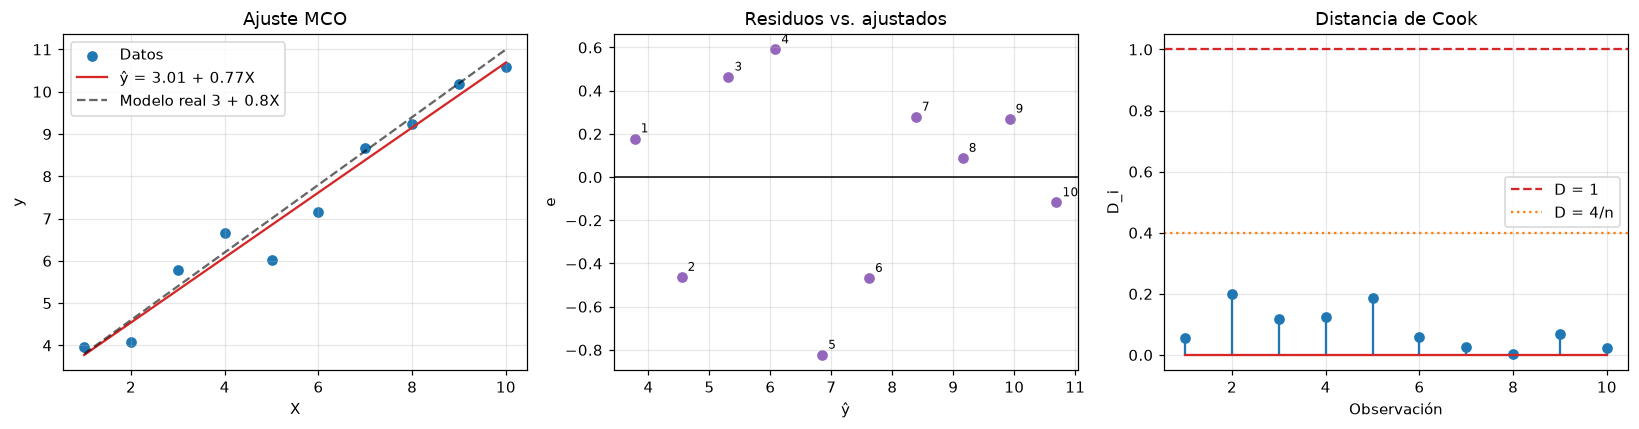

In [9]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))

ax[0].scatter(x, y, color="tab:blue", label="Datos")
ax[0].plot(x, y_hat, color="tab:red", label=f"ŷ = {b0:.2f} + {b1:.2f}X")
ax[0].plot(x, 3 + 0.8 * x, "k--", alpha=0.6, label="Modelo real 3 + 0.8X")
ax[0].set(title="Ajuste MCO", xlabel="X", ylabel="y"); ax[0].legend()

ax[1].scatter(y_hat, e, color="tab:purple")
ax[1].axhline(0, color="k", lw=1)
for i in range(n):
    ax[1].annotate(str(i + 1), (y_hat[i], e[i]), textcoords="offset points", xytext=(4, 4), fontsize=8)
ax[1].set(title="Residuos vs. ajustados", xlabel="ŷ", ylabel="e")

ax[2].stem(np.arange(1, n + 1), cook1)
ax[2].axhline(1, color="tab:red", ls="--", label="D = 1")
ax[2].axhline(4 / n, color="tab:orange", ls=":", label="D = 4/n")
ax[2].set(title="Distancia de Cook", xlabel="Observación", ylabel="D_i"); ax[2].legend()

plt.tight_layout(); plt.show()

In [10]:
# Verificación con statsmodels
m1 = sm.OLS(y, Xd).fit()
print(m1.summary(xname=["const", "X"]))
print("\nCook (statsmodels) coincide:", np.allclose(m1.get_influence().cooks_distance[0], cook1))

                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.963
Model:                            OLS   Adj. R-squared:                  0.958
Method:                 Least Squares   F-statistic:                     207.5
Date:                Fri, 20 Nov 2026   Prob (F-statistic):           5.28e-07
Time:                        11:38:01   Log-Likelihood:                -5.8303
No. Observations:                  10   AIC:                             15.66
Df Residuals:                       8   BIC:                             16.27
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          3.0052      0.331      9.077      0.0

### Conclusiones de la Parte 1

- **Estimación.** El modelo ajustado es $\hat y = 3.0052 + 0.7685\,X$, muy cercano al modelo real
  $y = 3 + 0.8X$. Ambos valores reales caen dentro de sus IC al 95 %
  ($\beta_0\in[2.24,\,3.77]$, $\beta_1\in[0.65,\,0.89]$).
- **Fórmulas vs. matrices.** $S_{xx}=82.5$, $S_{xy}=63.40$; la solución $(X^TX)^{-1}X^Ty$ reproduce
  exactamente los mismos $\hat\beta_0,\hat\beta_1$.
- **ANOVA.** $SST = SSR + SSE$ ($50.61 = 48.73 + 1.88$). $F = 207.46$ con $p \approx 5\times10^{-7}$ y
  $R^2 = 0.963$ (igual a $r^2 = 0.9813^2$): $X$ explica el 96 % de la variabilidad de $y$.
- **Pruebas $t$.** Intercepto ($t = 9.08$) y pendiente ($t = 14.40$) son significativos ($p<0.001$).
  Con $\hat\sigma = \sqrt{MSE} = 0.485$, prácticamente se recupera el $\sigma = 0.5$ del modelo generador.
- **$F = t^2$.** $14.4036^2 = 207.4648 = F_{calc}$: en regresión simple ambas pruebas son equivalentes.
- **Diagnóstico.** Los residuos no muestran patrón (ni curvatura ni embudo) alrededor de cero. Los
  extremos $X=1$ y $X=10$ tienen el mayor leverage ($h_{ii}=0.35$), pero ninguno supera $2p/n = 0.40$.
  La mayor distancia de Cook es $D_2 = 0.20$, muy lejos de 1 → **no hay puntos influyentes**.

---
# Parte 2: Regresión múltiple y multicolinealidad con `wine`

- **Respuesta:** `flavanoids`
- **Predictores:** `total_phenols`, `od280/od315_of_diluted_wines`, `proline`

In [11]:
data = load_wine()
X = pd.DataFrame(data.data, columns=data.feature_names)

resp = "flavanoids"
preds = ["total_phenols", "od280/od315_of_diluted_wines", "proline"]
abrev = {"total_phenols": "phenols", "od280/od315_of_diluted_wines": "od280", "proline": "proline"}

df2 = X[preds + [resp]].copy()
n2 = len(df2)
print(f"n = {n2} vinos")
display(df2.describe().T)

n = 178 vinos


,count,mean,std,min,25%,50%,75%,max
total_phenols,178.0000,2.2951,0.6259,0.9800,1.7425,2.3550,2.8000,3.8800
od280/od315_of_diluted_wines,178.0000,2.6117,0.7100,1.2700,1.9375,2.7800,3.1700,4.0000
proline,178.0000,746.8933,314.9075,278.0000,500.5000,673.5000,985.0000,"1,680.0000"
flavanoids,178.0000,2.0293,0.9989,0.3400,1.2050,2.1350,2.8750,5.0800


## 2.1 Exploración

In [12]:
corr = df2.corr().rename(index=abrev, columns=abrev)
print("Matriz de correlación (predictores + respuesta):")
display(corr)

corr_pred = corr.loc[list(abrev.values()), list(abrev.values())]
pares = corr_pred.where(np.triu(np.ones(corr_pred.shape, dtype=bool), k=1)).stack().dropna()
par_max = pares.abs().idxmax()
print("Correlaciones entre pares de predictores:")
print(pares.round(4).to_string())
print(f"\nPar más correlacionado: {par_max}  →  r = {pares[par_max]:.4f}")
print("\nCorrelación de cada predictor con flavanoids:")
print(corr.loc[list(abrev.values()), resp].round(4).to_string())

Matriz de correlación (predictores + respuesta):


,phenols,od280,proline,flavanoids
phenols,1.0000,0.6999,0.4981,0.8646
od280,0.6999,1.0000,0.3128,0.7872
proline,0.4981,0.3128,1.0000,0.4942
flavanoids,0.8646,0.7872,0.4942,1.0000


Correlaciones entre pares de predictores:
phenols  od280     0.6999
         proline   0.4981
od280    proline   0.3128

Par más correlacionado: ('phenols', 'od280')  →  r = 0.6999

Correlación de cada predictor con flavanoids:
phenols   0.8646
od280     0.7872
proline   0.4942


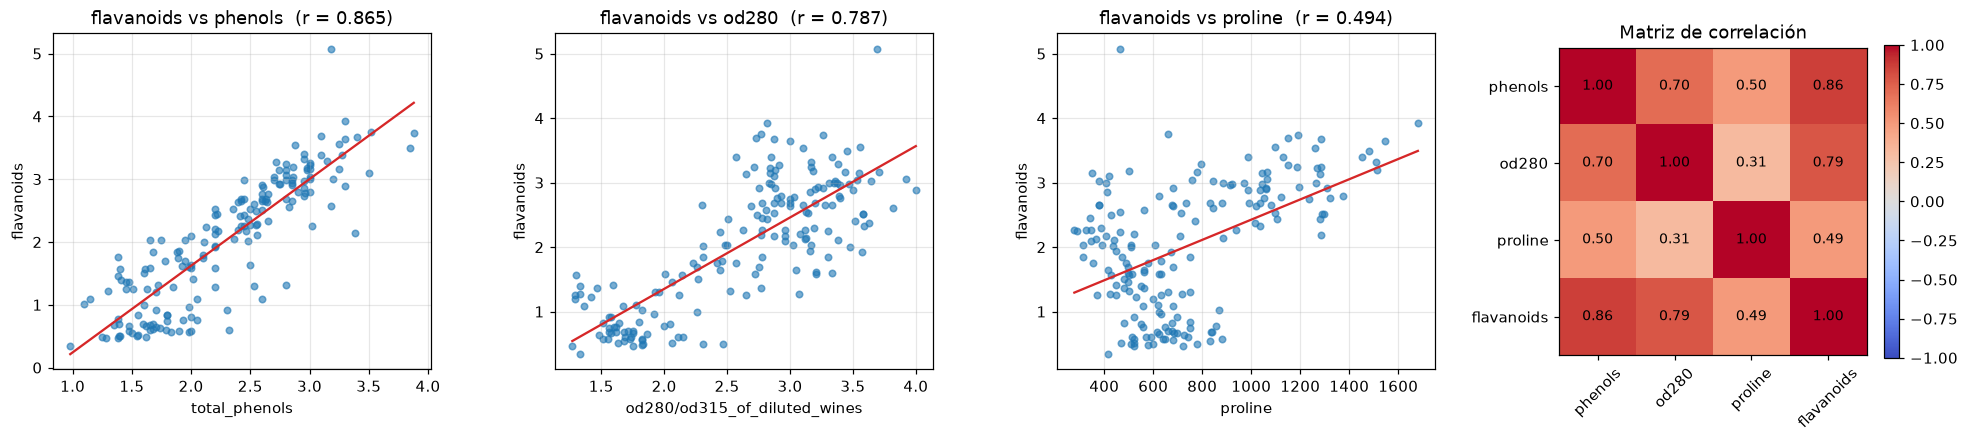

In [13]:
fig, ax = plt.subplots(1, 4, figsize=(18, 4), gridspec_kw={"width_ratios": [1, 1, 1, 0.9]})
for a, col in zip(ax[:3], preds):
    a.scatter(df2[col], df2[resp], alpha=0.6, s=18)
    pend, inter = np.polyfit(df2[col], df2[resp], 1)
    xs = np.linspace(df2[col].min(), df2[col].max(), 50)
    a.plot(xs, inter + pend * xs, color="tab:red")
    a.set(title=f"flavanoids vs {abrev[col]}  (r = {df2[col].corr(df2[resp]):.3f})",
          xlabel=col, ylabel="flavanoids")

im = ax[3].imshow(corr.values, cmap="coolwarm", vmin=-1, vmax=1)
ax[3].set_xticks(range(4), corr.columns, rotation=45); ax[3].set_yticks(range(4), corr.index)
for i in range(4):
    for j in range(4):
        ax[3].text(j, i, f"{corr.values[i, j]:.2f}", ha="center", va="center", fontsize=9)
ax[3].set_title("Matriz de correlación"); ax[3].grid(False)
fig.colorbar(im, ax=ax[3], fraction=0.046)
plt.tight_layout(); plt.show()

**Respuesta 2.1.** El par de predictores más correlacionado es **`total_phenols` – `od280/od315`**
($r = 0.70$), seguido de `total_phenols` – `proline` ($r = 0.50$) y `od280` – `proline` ($r = 0.31$).
Respecto a la respuesta, `total_phenols` es el predictor más asociado con `flavanoids` ($r = 0.86$),
luego `od280` ($r = 0.79$) y por último `proline` ($r = 0.49$). Esto tiene sentido químico: los
flavonoides son un subconjunto de los fenoles totales y ambos absorben en UV, igual que lo que mide
el cociente OD280/OD315. En las gráficas se ve una relación lineal clara con `total_phenols` y
`od280`, y una nube más dispersa con `proline`.

## 2.2 Solución matricial

$X_{design}=[\mathbf 1\mid X_1\mid X_2\mid X_3]$ ($n\times 4$), $\hat\beta=(X^TX)^{-1}X^Ty$ y
$SE(\hat\beta_j)=\sqrt{MSE\cdot[(X^TX)^{-1}]_{jj}}$.

In [14]:
def ols_matricial(Xmat, yvec):
    # Ajuste MCO explícito. Xmat ya incluye la columna de unos.
    n_, k_ = Xmat.shape                 # k_ = p + 1 parámetros
    XtX_inv_ = np.linalg.inv(Xmat.T @ Xmat)
    beta_ = XtX_inv_ @ Xmat.T @ yvec
    yhat_ = Xmat @ beta_
    e_ = yvec - yhat_
    SSE_ = e_ @ e_
    SST_ = np.sum((yvec - yvec.mean()) ** 2)
    SSR_ = SST_ - SSE_
    p_ = k_ - 1
    MSE_ = SSE_ / (n_ - k_)
    SE_ = np.sqrt(MSE_ * np.diag(XtX_inv_))
    return dict(beta=beta_, SE=SE_, yhat=yhat_, e=e_, SSE=SSE_, SSR=SSR_, SST=SST_,
                MSE=MSE_, n=n_, k=k_, p=p_, XtX_inv=XtX_inv_)

y2 = df2[resp].values
X2 = np.column_stack([np.ones(n2), df2[preds].values])   # n x 4
fit2 = ols_matricial(X2, y2)

nombres2 = ["const"] + preds
coef2 = pd.DataFrame({"β̂": fit2["beta"], "SE": fit2["SE"]}, index=nombres2)
coef2["t"] = coef2["β̂"] / coef2["SE"]
coef2["p-valor"] = 2 * stats.t.sf(np.abs(coef2["t"]), n2 - fit2["k"])
t_c2 = stats.t.ppf(0.975, n2 - fit2["k"])
coef2["IC95% inf"] = coef2["β̂"] - t_c2 * coef2["SE"]
coef2["IC95% sup"] = coef2["β̂"] + t_c2 * coef2["SE"]
print(f"Dimensión de X_design: {X2.shape}")
display(coef2.style.format("{:.6f}"))

Dimensión de X_design: (178, 4)


,β̂,SE,t,p-valor,IC95% inf,IC95% sup
const,-1.597353,0.133867,-11.932429,0.000000,-1.861565,-1.333142
total_phenols,0.892135,0.078816,11.319164,0.000000,0.736576,1.047694
od280/od315_of_diluted_wines,0.512193,0.063425,8.075537,0.000000,0.387011,0.637375
proline,0.000323,0.000118,2.743969,0.006707,0.000091,0.000556


> Nota: el coeficiente de `proline` se ve pequeño porque `proline` está en escala de cientos/miles
> (mg/L), mientras que `flavanoids` está en unidades de ~0.3–5. Su $t$ y su p-valor son los que
> indican si su efecto es relevante, no la magnitud cruda de $\hat\beta$.

## 2.3 Tabla ANOVA múltiple y prueba $F$ global

In [15]:
p2 = fit2["p"]
df_reg2, df_err2, df_tot2 = p2, n2 - p2 - 1, n2 - 1
MSR2 = fit2["SSR"] / df_reg2
MSE2 = fit2["SSE"] / df_err2
F2 = MSR2 / MSE2
pF2 = stats.f.sf(F2, df_reg2, df_err2)
R2_2 = fit2["SSR"] / fit2["SST"]
R2adj_2 = 1 - (fit2["SSE"] / df_err2) / (fit2["SST"] / df_tot2)

anova2 = pd.DataFrame({
    "SS": [fit2["SSR"], fit2["SSE"], fit2["SST"]],
    "df": [df_reg2, df_err2, df_tot2],
    "MS": [MSR2, MSE2, np.nan],
    "F": [F2, np.nan, np.nan],
    "p-valor": [pF2, np.nan, np.nan],
}, index=["Regresión", "Error", "Total"])
display(anova2)
print(f"F crítico (0.95; {df_reg2}, {df_err2}) = {stats.f.ppf(0.95, df_reg2, df_err2):.4f}")
print(f"Prueba F global: F = {F2:.4f}, p = {pF2:.3e}  →  "
      f"{'se rechaza' if pF2 < 0.05 else 'no se rechaza'} H0: β1 = β2 = β3 = 0")
print(f"R² = {R2_2:.4f}     R²_adj = {R2adj_2:.4f}")

,SS,df,MS,F,p-valor
Regresión,144.8478,3,48.2826,264.6172,0.0000
Error,31.7484,174,0.1825,NaN,NaN
Total,176.5962,177,NaN,NaN,NaN


F crítico (0.95; 3, 174) = 2.6565
Prueba F global: F = 264.6172, p = 1.393e-64  →  se rechaza H0: β1 = β2 = β3 = 0
R² = 0.8202     R²_adj = 0.8171


## 2.4 Multicolinealidad (VIF)

Para cada $X_j$ se ajusta la regresión auxiliar $X_j \sim$ (resto de predictores) y
$VIF_j = 1/(1-R_j^2)$.

In [16]:
vif_rows = []
for col in preds:
    otros = [c for c in preds if c != col]
    Xaux = np.column_stack([np.ones(n2), df2[otros].values])
    aux = ols_matricial(Xaux, df2[col].values)
    Rj2 = aux["SSR"] / aux["SST"]
    vif_rows.append({"Variable": col, "Regresores auxiliares": ", ".join(abrev[o] for o in otros),
                     "R²_j": Rj2, "VIF": 1 / (1 - Rj2)})
vif_df = pd.DataFrame(vif_rows).set_index("Variable")
display(vif_df)

# Verificación con statsmodels
from statsmodels.stats.outliers_influence import variance_inflation_factor
print("VIF statsmodels:", [round(variance_inflation_factor(X2, i), 4) for i in range(1, 4)])
print("¿Algún VIF > 10?", (vif_df["VIF"] > 10).any(), "| ¿Algún VIF > 5?", (vif_df["VIF"] > 5).any())
var_max_vif = vif_df["VIF"].idxmax()
print(f"Variable con mayor VIF: {var_max_vif} (VIF = {vif_df.loc[var_max_vif, 'VIF']:.4f})")

,Regresores auxiliares,R²_j,VIF
Variable,,,
total_phenols,"od280, proline",0.5763,2.3603
od280/od315_of_diluted_wines,"phenols, proline",0.4916,1.9671
proline,"phenols, od280",0.2506,1.3345


VIF statsmodels: [np.float64(2.3603), np.float64(1.9671), np.float64(1.3345)]
¿Algún VIF > 10? False | ¿Algún VIF > 5? False
Variable con mayor VIF: total_phenols (VIF = 2.3603)


**Respuesta 2.4.** Los VIF son **2.36** (`total_phenols`), **1.97** (`od280`) y **1.33** (`proline`).
**Ninguna variable presenta multicolinealidad grave** (todos los VIF $< 10$, e incluso $< 5$). La que
tiene el VIF más alto es `total_phenols`, porque es la mejor explicada por las otras dos
($R_j^2 = 0.58$): está correlacionada 0.70 con `od280` y 0.50 con `proline`. En términos prácticos,
su varianza muestral está inflada $\approx 2.4$ veces respecto a si fuera ortogonal a las demás
(su SE crece $\sqrt{2.36}\approx 1.54$ veces): hay **colinealidad moderada, no grave**, y los
coeficientes se pueden interpretar con confianza.

## 2.5 Leverage y distancia de Cook

$H = X(X^TX)^{-1}X^T$, $h_{ii}$ = diagonal de $H$. El enunciado pide el umbral $2p/n$ con $p=3$;
como referencia también se muestra el umbral más usado en la literatura, $2(p+1)/n$ (con $p+1=4$
parámetros incluyendo el intercepto). En Cook se usa el número de parámetros $k=p+1=4$.

In [17]:
H2 = X2 @ fit2["XtX_inv"] @ X2.T
h2 = np.diag(H2)
print(f"traza(H) = {h2.sum():.4f}  (debe ser igual al número de parámetros = {fit2['k']})")

k2 = fit2["k"]
cook2 = (fit2["e"] ** 2 / (k2 * MSE2)) * (h2 / (1 - h2) ** 2)

umbral_h = 2 * p2 / n2
umbral_h_alt = 2 * (p2 + 1) / n2
diag2 = df2.rename(columns=abrev).assign(h_ii=h2, Cook=cook2, e=fit2["e"])

alto_lev = diag2[diag2["h_ii"] > umbral_h]
print(f"Umbral 2p/n = {umbral_h:.4f}  →  {len(alto_lev)} observaciones con leverage alto")
print(f"Umbral 2(p+1)/n = {umbral_h_alt:.4f}  →  {(h2 > umbral_h_alt).sum()} observaciones")
display(alto_lev.sort_values("h_ii", ascending=False))

print(f"Máxima distancia de Cook = {cook2.max():.4f} (obs. {cook2.argmax()})")
print("Observaciones con D_i > 1:", [int(i) for i in np.where(cook2 > 1)[0]] or "ninguna")
print(f"Observaciones con D_i > 4/n = {4/n2:.4f} (criterio más estricto):", [int(i) for i in np.where(cook2 > 4 / n2)[0]])

# Verificación
m2 = sm.OLS(y2, X2).fit()
print("\n¿h_ii y Cook coinciden con statsmodels?",
      np.allclose(m2.get_influence().hat_matrix_diag, h2), np.allclose(m2.get_influence().cooks_distance[0], cook2))

traza(H) = 4.0000  (debe ser igual al número de parámetros = 4)
Umbral 2p/n = 0.0337  →  25 observaciones con leverage alto
Umbral 2(p+1)/n = 0.0449  →  8 observaciones


,phenols,od280,proline,flavanoids,h_ii,Cook,e
63,3.5000,2.8700,420.0000,3.1000,0.0695,0.0001,-0.0309
18,3.3000,2.8200,"1,680.0000",3.9300,0.0612,0.0338,0.5960
98,3.5200,2.7700,660.0000,3.7500,0.0552,0.0280,0.5750
3,3.8500,3.4500,"1,480.0000",3.4900,0.0523,0.0280,-0.5927
52,3.8800,3.2600,"1,190.0000",3.7400,0.0501,0.0024,-0.1785
152,2.2000,1.3300,425.0000,1.2800,0.0463,0.0006,0.0961
105,1.6800,3.3000,315.0000,1.8400,0.0459,0.0015,0.1465
14,3.3000,3.0000,"1,547.0000",3.6400,0.0457,0.0045,0.2568
94,3.0200,2.9600,345.0000,2.2600,0.0409,0.0131,-0.4645
6,2.5000,3.5800,"1,290.0000",2.5200,0.0408,0.0080,-0.3635


Máxima distancia de Cook = 0.1844 (obs. 121)
Observaciones con D_i > 1: ninguna
Observaciones con D_i > 4/n = 0.0225 (criterio más estricto): [3, 18, 74, 98, 121, 132, 139, 149, 150, 158, 159]

¿h_ii y Cook coinciden con statsmodels? True True


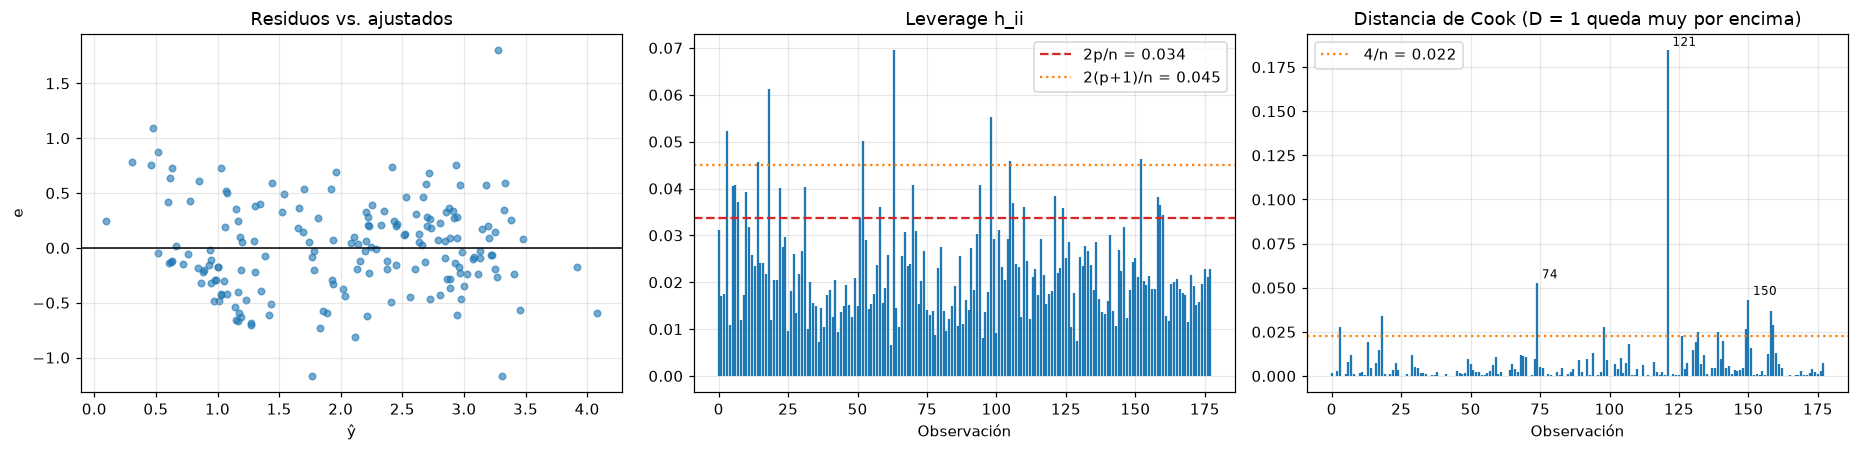

In [18]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.2))
idx = np.arange(n2)

ax[0].scatter(fit2["yhat"], fit2["e"], alpha=0.6, s=18)
ax[0].axhline(0, color="k", lw=1)
ax[0].set(title="Residuos vs. ajustados", xlabel="ŷ", ylabel="e")

ax[1].stem(idx, h2, markerfmt=" ", basefmt=" ")
ax[1].axhline(umbral_h, color="tab:red", ls="--", label=f"2p/n = {umbral_h:.3f}")
ax[1].axhline(umbral_h_alt, color="tab:orange", ls=":", label=f"2(p+1)/n = {umbral_h_alt:.3f}")
ax[1].set(title="Leverage h_ii", xlabel="Observación"); ax[1].legend()

ax[2].stem(idx, cook2, markerfmt=" ", basefmt=" ")
ax[2].axhline(4 / n2, color="tab:orange", ls=":", label=f"4/n = {4/n2:.3f}")
for i in np.argsort(cook2)[-3:]:
    ax[2].annotate(str(i), (i, cook2[i]), textcoords="offset points", xytext=(3, 3), fontsize=8)
ax[2].set(title="Distancia de Cook (D = 1 queda muy por encima)", xlabel="Observación"); ax[2].legend()
plt.tight_layout(); plt.show()

**Respuesta 2.5.**
- **Leverage.** Con el umbral pedido $2p/n = 6/178 = 0.0337$ hay **25 observaciones** con leverage alto;
  con el umbral convencional $2(p+1)/n = 0.0449$ quedan **8** (obs. 63, 18, 98, 3, 52, 152, 105 y 14).
  Son vinos con valores extremos en el espacio de predictores: p. ej. las obs. 18 y 3 tienen `proline`
  de 1680 y 1480 (las más altas), y las obs. 63 y 52 tienen `total_phenols` muy altos.
- **Influencia.** La mayor distancia de Cook es $D_{121} = 0.18$, así que **ninguna observación es
  influyente con el criterio $D_i > 1$**. La obs. 121 destaca por residuo, no por leverage: tiene el
  valor máximo de `flavanoids` (5.08) y el modelo la subestima por 1.8 unidades. Con el criterio más
  estricto $4/n = 0.022$ se marcan 11 observaciones para revisión, pero ninguna mueve el ajuste de
  forma importante.
- Tener leverage alto no implica ser influyente: la obs. 63 tiene el $h_{ii}$ más grande (0.07) pero un
  residuo casi nulo, por lo que su $D_i \approx 0$.

## 2.6 Comparación de modelos: completo vs. reducido

Se elimina la variable con mayor VIF. Log-verosimilitud gaussiana evaluada en el MLE
$\hat\sigma^2 = SSE/n$:
$$\log L = -\frac n2\left[\log(2\pi) + \log\!\left(\frac{SSE}{n}\right) + 1\right]$$
con $k$ = número de coeficientes estimados (intercepto incluido), igual que en `statsmodels`.

In [19]:
def metricas(fit):
    n_, k_ = fit["n"], fit["k"]
    logL = -n_ / 2 * (np.log(2 * np.pi) + np.log(fit["SSE"] / n_) + 1)
    R2_ = fit["SSR"] / fit["SST"]
    R2a = 1 - (fit["SSE"] / (n_ - k_)) / (fit["SST"] / (n_ - 1))
    return {"k": k_, "R²": R2_, "R²_adj": R2a, "log L": logL,
            "AIC": -2 * logL + 2 * k_, "BIC": -2 * logL + k_ * np.log(n_)}

preds_red = [c for c in preds if c != var_max_vif]
X2r = np.column_stack([np.ones(n2), df2[preds_red].values])
fit2r = ols_matricial(X2r, y2)

comp = pd.DataFrame({"Completo (3 predictores)": metricas(fit2),
                     f"Reducido (sin {abrev[var_max_vif]})": metricas(fit2r)}).T
display(comp)

# Verificación con statsmodels
m2r = sm.OLS(y2, X2r).fit()
print("statsmodels  completo: AIC = %.4f  BIC = %.4f" % (m2.aic, m2.bic))
print("statsmodels  reducido: AIC = %.4f  BIC = %.4f" % (m2r.aic, m2r.bic))

,k,R²,R²_adj,log L,AIC,BIC
Completo (3 predictores),4.0000,0.8202,0.8171,-99.1403,206.2806,219.0077
Reducido (sin phenols),3.0000,0.6878,0.6843,-148.2488,302.4975,312.0429


statsmodels  completo: AIC = 206.2806  BIC = 219.0077
statsmodels  reducido: AIC = 302.4975  BIC = 312.0429


In [20]:
# ¿Cambian los coeficientes al quitar la variable?
coef_red = pd.Series(fit2r["beta"], index=["const"] + preds_red)
cambio = pd.DataFrame({"β̂ completo": coef2["β̂"], "β̂ reducido": coef_red})
cambio["SE completo"] = coef2["SE"]
cambio["SE reducido"] = pd.Series(fit2r["SE"], index=["const"] + preds_red)
signo = np.where(cambio["β̂ reducido"].isna(), "— (eliminada)",
                 np.where(np.sign(cambio["β̂ completo"]) != np.sign(cambio["β̂ reducido"]), "Sí", "No"))
cambio["¿Cambia de signo?"] = signo
display(cambio)

# Prueba F parcial (modelos anidados)
F_parc = ((fit2r["SSE"] - fit2["SSE"]) / 1) / MSE2
print(f"Prueba F parcial para {var_max_vif}: F = {F_parc:.4f}, p = {stats.f.sf(F_parc, 1, df_err2):.3e}"
      f"  (= t² = {coef2.loc[var_max_vif, 't']**2:.4f})")

,β̂ completo,β̂ reducido,SE completo,SE reducido,¿Cambia de signo?
const,-1.5974,-1.1984,0.1339,0.1697,No
od280/od315_of_diluted_wines,0.5122,0.9865,0.0634,0.0626,No
proline,0.0003,0.0009,0.0001,0.0001,No
total_phenols,0.8921,NaN,0.0788,NaN,— (eliminada)


Prueba F parcial para total_phenols: F = 128.1235, p = 1.305e-22  (= t² = 128.1235)


**Respuesta 2.6.** Se elimina `total_phenols` (mayor VIF).

| Métrica | Completo | Reducido | Mejor |
|---|---|---|---|
| $R^2_{adj}$ | 0.817 | 0.684 | Completo |
| AIC | 206.3 | 302.5 | Completo |
| BIC | 219.0 | 312.0 | Completo |

El modelo completo es claramente superior en los tres criterios (ΔAIC ≈ 96, ΔBIC ≈ 93; diferencias
mayores a 10 ya se consideran evidencia muy fuerte). La prueba $F$ parcial confirma que
`total_phenols` aporta información propia ($F = 128.1$, $p \approx 10^{-22}$). Es decir: **un VIF
moderado no justifica eliminar una variable** que es el predictor más fuerte de la respuesta.

Ningún coeficiente cambia de signo, pero sí de magnitud: el de `od280` casi se duplica
(0.51 → 0.99) y el de `proline` se triplica (0.0003 → 0.0009). Al quitar `total_phenols`, los
predictores correlacionados con ella "absorben" su efecto (sesgo por variable omitida).

## 2.7 Preguntas

**¿Qué información aporta el VIF que el $R^2$ no captura?**

El $R^2$ es una medida **global** de ajuste: dice qué tanto de la variabilidad de $y$ explica el
conjunto de predictores, pero no dice nada sobre la relación de los predictores **entre sí**. Un
modelo puede tener $R^2 = 0.95$ y aun así coeficientes individuales inestables. El VIF es una medida
**por coeficiente**: $VIF_j$ dice cuántas veces se infla $\operatorname{Var}(\hat\beta_j)$ por la
redundancia de $X_j$ con los demás predictores. Por eso un VIF alto anticipa errores estándar grandes,
IC anchos, pruebas $t$ no significativas a pesar de una $F$ global muy significativa, y coeficientes
que cambian mucho al agregar o quitar variables o al cambiar ligeramente la muestra.

*Ejemplo aplicado:* si a este modelo se le agregara `total_phenols` por segunda vez, ahora en otra
unidad (p. ej. multiplicada por 1000), el $R^2$ no cambiaría en absoluto (0.82), pero los VIF de esas
dos columnas se irían a infinito y sus coeficientes serían indeterminados: el $R^2$ no da ninguna
señal de alarma y el VIF sí. En nuestro
caso, con $R^2 = 0.82$ el VIF máximo es 2.4, lo que confirma que el buen ajuste no viene acompañado de
coeficientes inestables.

**¿Qué implica que un coeficiente cambie de signo al eliminar otra variable?**

Implica que la variable eliminada estaba correlacionada tanto con ese predictor como con la
respuesta, y que el coeficiente en cada modelo **responde a una pregunta distinta**: en el modelo
completo $\hat\beta_j$ es el efecto de $X_j$ *manteniendo constantes las demás*; en el reducido es el
efecto de $X_j$ más la parte del efecto de la variable omitida que viaja con $X_j$ (sesgo por
variable omitida, $\text{sesgo}=\beta_{omit}\cdot\delta$, con $\delta$ la pendiente de la variable
omitida sobre $X_j$). Un cambio de signo es un síntoma clásico de multicolinealidad fuerte o de un
efecto de confusión (paradoja de Simpson), y advierte que **no debe interpretarse causalmente** el
signo del coeficiente sin entender la estructura de correlación. En nuestro caso no hubo cambio de
signo (la colinealidad es moderada), pero el coeficiente de `od280` sí se duplicó, lo que muestra el
mismo mecanismo en menor escala.

---
# Parte 3 (EXTRA): Regresión logística binaria sobre `iris`

## 3.1 Preparación de los datos

Se conservan solo *versicolor* (clase 1) y *virginica* (clase 2), se recodifica a
$\{0,1\}$ (versicolor = 0, virginica = 1), se divide 80/20 con estratificación y se estandariza
**con la media y desviación del conjunto de entrenamiento** (para no filtrar información del
conjunto de prueba).

In [21]:
data_iris = load_iris()
Xi = pd.DataFrame(data_iris.data, columns=data_iris.feature_names)
yi_orig = pd.Series(data_iris.target)

mask = yi_orig.isin([1, 2])
Xi = Xi[mask].reset_index(drop=True)
yi = (yi_orig[mask] == 2).astype(int).reset_index(drop=True)    # versicolor=0, virginica=1
print(f"n = {len(yi)}  |  conteo por clase:", yi.value_counts().sort_index().to_dict())

Xtr, Xte, ytr, yte = train_test_split(Xi, yi, test_size=0.2, stratify=yi, random_state=SEED)
scaler = StandardScaler().fit(Xtr)
Xtr_s = pd.DataFrame(scaler.transform(Xtr), columns=Xi.columns, index=Xtr.index)
Xte_s = pd.DataFrame(scaler.transform(Xte), columns=Xi.columns, index=Xte.index)

print(f"Entrenamiento: {len(ytr)} obs {ytr.value_counts().sort_index().to_dict()}")
print(f"Prueba:        {len(yte)} obs {yte.value_counts().sort_index().to_dict()}")
display(Xtr_s.describe().loc[["mean", "std"]])

n = 100  |  conteo por clase: {0: 50, 1: 50}
Entrenamiento: 80 obs {0: 40, 1: 40}
Prueba:        20 obs {0: 10, 1: 10}


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
mean,0.0000,0.0000,-0.0000,0.0000
std,1.0063,1.0063,1.0063,1.0063


## 3.2 Ajuste de la regresión logística

Se ajusta por máxima verosimilitud (`statsmodels.Logit`, sin regularización) para obtener errores
estándar, estadísticos $z$ y p-valores de Wald. $OR_j = e^{\hat\beta_j}$, con IC al 95 %
$\left[e^{\hat\beta_j-1.96\,SE_j},\ e^{\hat\beta_j+1.96\,SE_j}\right]$.

In [22]:
Xtr_c = sm.add_constant(Xtr_s)
Xte_c = sm.add_constant(Xte_s, has_constant="add")
logit = sm.Logit(ytr, Xtr_c).fit(disp=0)
print(logit.summary())

z975 = stats.norm.ppf(0.975)
tab3 = pd.DataFrame({
    "β̂": logit.params, "SE": logit.bse, "z": logit.tvalues, "p-valor": logit.pvalues,
})
tab3["OR = e^β̂"] = np.exp(tab3["β̂"])
tab3["OR IC95% inf"] = np.exp(tab3["β̂"] - z975 * tab3["SE"])
tab3["OR IC95% sup"] = np.exp(tab3["β̂"] + z975 * tab3["SE"])
tab3["Signif. (α=0.05)"] = tab3["p-valor"] < 0.05
display(tab3)
print(f"Pseudo-R² de McFadden = {logit.prsquared:.4f}   |   LR χ² = {logit.llr:.3f}, p = {logit.llr_pvalue:.3e}")

                           Logit Regression Results                           
Dep. Variable:                      y   No. Observations:                   80
Model:                          Logit   Df Residuals:                       75
Method:                           MLE   Df Model:                            4
Date:                Fri, 20 Nov 2026   Pseudo R-squ.:                  0.9231
Time:                        11:38:02   Log-Likelihood:                -4.2638
converged:                       True   LL-Null:                       -55.452
Covariance Type:            nonrobust   LLR p-value:                 3.068e-21
                        coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------
const                 0.4477      0.948      0.472      0.637      -1.411       2.306
sepal length (cm)    -1.1384      2.244     -0.507      0.612      -5.536       3.260
sepal width (cm)     -0.

,β̂,SE,z,p-valor,OR = e^β̂,OR IC95% inf,OR IC95% sup,Signif. (α=0.05)
const,0.4477,0.9483,0.4721,0.6369,1.5647,0.2439,10.0374,False
sepal length (cm),-1.1384,2.2439,-0.5073,0.6119,0.3203,0.0039,26.0389,False
sepal width (cm),-0.8174,2.0913,-0.3908,0.6959,0.4416,0.0073,26.6139,False
petal length (cm),5.5039,4.0819,1.3484,0.1775,245.6535,0.0824,"732,551.5808",False
petal width (cm),6.5176,3.2553,2.0022,0.0453,676.9824,1.1473,"399,465.3175",True


Pseudo-R² de McFadden = 0.9231   |   LR χ² = 102.376, p = 3.068e-21


## 3.3 Interpretación de los odds ratios

In [23]:
top2 = tab3.drop("const")["β̂"].abs().sort_values(ascending=False).index[:2]
for v in top2:
    b, OR, lo, hi = tab3.loc[v, ["β̂", "OR = e^β̂", "OR IC95% inf", "OR IC95% sup"]]
    sd = scaler.scale_[list(Xi.columns).index(v)]
    print(f"{v}: β̂ = {b:.3f}  →  OR = {OR:.2f}  (IC95%: {lo:.2f} – {hi:.2f});  1 DE = {sd:.3f} cm")

petal width (cm): β̂ = 6.518  →  OR = 676.98  (IC95%: 1.15 – 399465.32);  1 DE = 0.439 cm
petal length (cm): β̂ = 5.504  →  OR = 245.65  (IC95%: 0.08 – 732551.58);  1 DE = 0.814 cm


**Respuesta 3.3.** Las dos variables con mayor $|\hat\beta_j|$ son **`petal width`** ($\hat\beta = 6.52$) y
**`petal length`** ($\hat\beta = 5.50$). Como los predictores están estandarizados, los OR se
interpretan **por cada desviación estándar** de aumento, manteniendo constantes las otras tres medidas:

- **Ancho del pétalo, OR ≈ 677.** Por cada 1 DE (≈ 0.44 cm) que aumenta el ancho del pétalo, las
  *odds* de que la flor sea *virginica* (frente a *versicolor*) se multiplican por ~677. Ejemplo: una
  flor con odds 1:1 (probabilidad 0.5) que tuviera el pétalo 0.44 cm más ancho pasaría a odds
  677:1, es decir, $p \approx 0.9985$. Su IC al 95 % (1.15 – 399 465) **no incluye el 1**, por lo que el
  efecto es significativo, aunque su magnitud exacta está muy mal determinada.
- **Largo del pétalo, OR ≈ 246.** Por cada 1 DE (≈ 0.81 cm) más de largo del pétalo, las odds de
  *virginica* se multiplican por ~246. Sin embargo, su IC (0.08 – 732 552) **incluye el 1**, así que
  con estos datos no se puede descartar que no tenga efecto *adicional* una vez que se controla por
  el ancho del pétalo (ambas medidas están muy correlacionadas, $r \approx 0.82$).

Los OR tan grandes y los IC tan anchos se deben a que las dos especies están **casi separadas**
(statsmodels advierte cuasi-separación: el 46 % de las observaciones se predicen perfectamente). En
esa situación la verosimilitud se vuelve muy plana en la dirección de los coeficientes y los SE de
Wald se inflan, de modo que la dirección del efecto es confiable, pero su tamaño exacto no.

## 3.4 Evaluación en el conjunto de prueba

In [24]:
p_te = logit.predict(Xte_c)
yhat_te = (p_te >= 0.5).astype(int)

cm = confusion_matrix(yte, yhat_te, labels=[0, 1])
TN, FP, FN, TP = cm.ravel()
acc = (TP + TN) / cm.sum()
sens = TP / (TP + FN)          # recall de virginica
espec = TN / (TN + FP)         # recall de versicolor
auc = roc_auc_score(yte, p_te)

display(pd.DataFrame(cm, index=["Real: versicolor (0)", "Real: virginica (1)"],
                     columns=["Pred: versicolor (0)", "Pred: virginica (1)"]))
print(f"Accuracy       = {acc:.4f}")
print(f"Sensibilidad   = {sens:.4f}   (virginica correctamente detectadas)")
print(f"Especificidad  = {espec:.4f}   (versicolor correctamente detectadas)")
print(f"AUC (prueba)   = {auc:.4f}")
print(f"AUC (entrenamiento) = {roc_auc_score(ytr, logit.predict(Xtr_c)):.4f}")

,Pred: versicolor (0),Pred: virginica (1)
Real: versicolor (0),9,1
Real: virginica (1),0,10


Accuracy       = 0.9500
Sensibilidad   = 1.0000   (virginica correctamente detectadas)
Especificidad  = 0.9000   (versicolor correctamente detectadas)
AUC (prueba)   = 0.9900
AUC (entrenamiento) = 0.9987


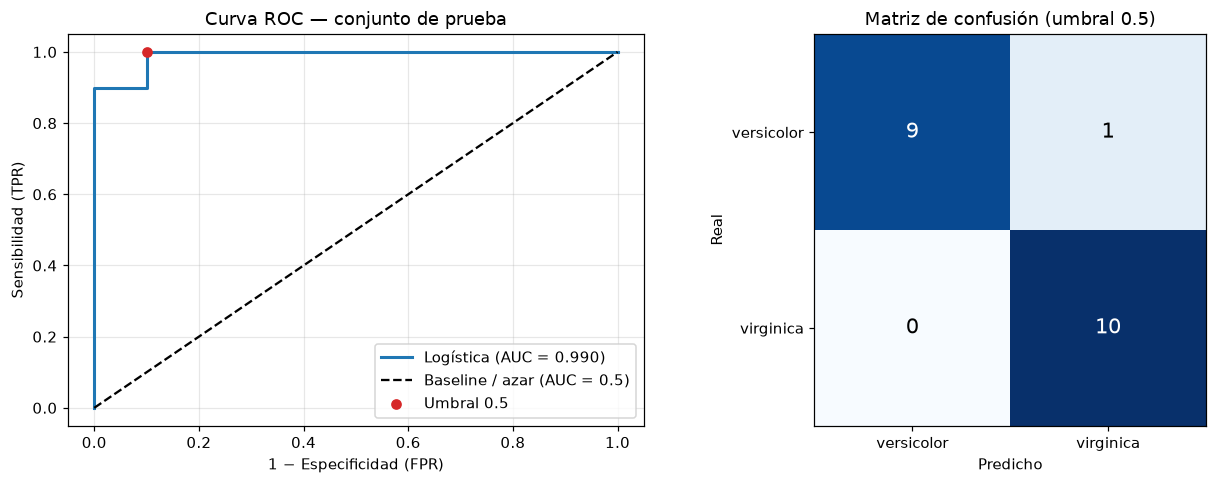

In [25]:
fpr, tpr, thr = roc_curve(yte, p_te)
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))

ax[0].plot(fpr, tpr, color="tab:blue", lw=2, label=f"Logística (AUC = {auc:.3f})")
ax[0].plot([0, 1], [0, 1], "k--", label="Baseline / azar (AUC = 0.5)")
ax[0].scatter(1 - espec, sens, color="tab:red", zorder=5, label="Umbral 0.5")
ax[0].set(title="Curva ROC — conjunto de prueba", xlabel="1 − Especificidad (FPR)",
          ylabel="Sensibilidad (TPR)"); ax[0].legend(loc="lower right")

im = ax[1].imshow(cm, cmap="Blues")
for i in range(2):
    for j in range(2):
        ax[1].text(j, i, cm[i, j], ha="center", va="center", fontsize=14,
                   color="white" if cm[i, j] > cm.max() / 2 else "black")
ax[1].set_xticks([0, 1], ["versicolor", "virginica"]); ax[1].set_yticks([0, 1], ["versicolor", "virginica"])
ax[1].set(title="Matriz de confusión (umbral 0.5)", xlabel="Predicho", ylabel="Real"); ax[1].grid(False)
plt.tight_layout(); plt.show()

## 3.5 Baseline: clasificador de la clase mayoritaria

El baseline predice siempre la clase más frecuente del entrenamiento y asigna la misma probabilidad a
todas las observaciones, por lo que no puede ordenar casos y su AUC es 0.5.

In [26]:
clase_mayor = ytr.value_counts().idxmax()          # en empate 40/40, idxmax toma la primera (0)
print("Conteos de entrenamiento:", ytr.value_counts().sort_index().to_dict(), "→ clase mayoritaria =", clase_mayor)

yhat_base = np.full(len(yte), clase_mayor)
p_base = np.full(len(yte), ytr.mean())             # probabilidad constante
acc_base = accuracy_score(yte, yhat_base)
auc_base = roc_auc_score(yte, p_base)

comp3 = pd.DataFrame({"Accuracy": [acc_base, acc], "AUC": [auc_base, auc]},
                     index=["Baseline (clase mayoritaria)", "Regresión logística"])
comp3.loc["Mejora (puntos)"] = comp3.iloc[1] - comp3.iloc[0]
display(comp3)
print(f"Mejora en accuracy: {acc - acc_base:+.2f}  ({(acc - acc_base) / acc_base:+.0%} relativo)")
print(f"Mejora en AUC:      {auc - auc_base:+.2f}")

Conteos de entrenamiento: {0: 40, 1: 40} → clase mayoritaria = 0


,Accuracy,AUC
Baseline (clase mayoritaria),0.5000,0.5000
Regresión logística,0.9500,0.9900
Mejora (puntos),0.4500,0.4900


Mejora en accuracy: +0.45  (+90% relativo)
Mejora en AUC:      +0.49


## 3.6 Preguntas

Antes de responder se calcula la prueba de **Hosmer–Lemeshow** (con $g$ grupos por cuantiles de la
probabilidad predicha) para tener evidencia concreta, y se hace un experimento rápido con
*setosa vs. resto*.

In [27]:
def hosmer_lemeshow(y_true, p_pred, g=10):
    d = pd.DataFrame({"y": np.asarray(y_true), "p": np.asarray(p_pred)})
    d["grupo"] = pd.qcut(d["p"].rank(method="first"), g, labels=False)
    t = d.groupby("grupo").agg(n=("y", "size"), obs=("y", "sum"), esp=("p", "sum"))
    hl = (((t["obs"] - t["esp"]) ** 2) / (t["esp"] * (1 - t["esp"] / t["n"]))).sum()
    return hl, stats.chi2.sf(hl, g - 2), t

for g in (10, 8, 5):
    hl, p_hl, _ = hosmer_lemeshow(ytr, logit.predict(Xtr_c), g)
    print(f"Hosmer–Lemeshow (entrenamiento, g = {g:>2}): χ² = {hl:7.3f},  p = {p_hl:.3f}")

Hosmer–Lemeshow (entrenamiento, g = 10): χ² =   0.136,  p = 1.000
Hosmer–Lemeshow (entrenamiento, g =  8): χ² =   0.100,  p = 1.000
Hosmer–Lemeshow (entrenamiento, g =  5): χ² =   0.046,  p = 0.997


In [28]:
# Experimento: setosa (1) vs. resto (0)  →  50 vs. 100, desbalance 1:2
y_set = (yi_orig == 0).astype(int)
Xs = pd.DataFrame(data_iris.data, columns=data_iris.feature_names)
Xs_tr, Xs_te, ys_tr, ys_te = train_test_split(Xs, y_set, test_size=0.2, stratify=y_set, random_state=SEED)
sc_s = StandardScaler().fit(Xs_tr)

print("Baseline 'siempre resto' — accuracy en prueba:", round(accuracy_score(ys_te, np.zeros(len(ys_te))), 4), "| AUC = 0.5")
import warnings
with warnings.catch_warnings(record=True) as w:
    warnings.simplefilter("always")
    try:
        res_s = sm.Logit(ys_tr, sm.add_constant(sc_s.transform(Xs_tr))).fit(disp=0, maxiter=100)
        sep = any("separation" in str(wi.message).lower() for wi in w)
        print(f"Logit MLE sin regularizar → ¿separación perfecta detectada? {sep}")
        print("  |β̂| máximo =", round(float(np.abs(res_s.params).max()), 2),
              "| SE máximo =", f"{float(np.nanmax(res_s.bse)):.2e}", "(los coeficientes divergen: el MLE no existe)")
    except Exception as err:
        print("Logit MLE sin regularizar falló:", type(err).__name__, "→", str(err)[:90])

from sklearn.linear_model import LogisticRegression
lr_s = LogisticRegression().fit(sc_s.transform(Xs_tr), ys_tr)
ps = lr_s.predict_proba(sc_s.transform(Xs_te))[:, 1]
print("Logística regularizada (sklearn) — accuracy:", round(accuracy_score(ys_te, ps >= 0.5), 4),
      "| AUC:", round(roc_auc_score(ys_te, ps), 4))

Baseline 'siempre resto' — accuracy en prueba: 0.6667 | AUC = 0.5
Logit MLE sin regularizar → ¿separación perfecta detectada? True
  |β̂| máximo = 17.71 | SE máximo = 3.85e+05 (los coeficientes divergen: el MLE no existe)
Logística regularizada (sklearn) — accuracy: 1.0 | AUC: 1.0


**¿Qué variables son significativas?** Con la prueba de Wald al 5 %, solo **`petal width`**
($p = 0.045$). `petal length` no lo es ($p = 0.18$), ni las medidas del sépalo ($p > 0.6$). Aun así, el
modelo en conjunto es altamente significativo (prueba de razón de verosimilitudes $\chi^2_4 = 102.4$,
$p \approx 3\times10^{-21}$; pseudo-$R^2$ de McFadden = 0.92). La aparente contradicción se explica
por la cuasi-separación y la correlación entre las medidas del pétalo: juntas discriminan muy bien,
pero los SE de Wald están inflados y cuesta atribuir el efecto a una sola variable.

**¿El modelo clasifica bien?** Sí. En el conjunto de prueba (20 flores no vistas): accuracy = 0.95,
sensibilidad = 1.00 (las 10 *virginica* detectadas), especificidad = 0.90 (1 *versicolor* clasificada
como *virginica*) y AUC = 0.99. Frente al baseline (accuracy 0.50, AUC 0.50) mejora 45 puntos de
accuracy y 49 de AUC. El AUC de entrenamiento (0.999) y el de prueba (0.99) son muy parecidos, así
que no hay señal de sobreajuste, aunque con 20 observaciones de prueba cada error vale 5 puntos.

**Limitaciones de usar Hosmer–Lemeshow como único criterio.**
1. **Mide calibración, no discriminación.** HL compara probabilidades predichas vs. frecuencias
   observadas por grupo; un modelo que predijera $p = 0.5$ para todas las flores estaría
   perfectamente calibrado (HL no rechaza) y sería inútil para clasificar.
2. **Depende del número de grupos $g$** y de cómo se forman: distintos $g$ pueden dar p-valores
   distintos.
3. **Bajo poder con muestras pequeñas** (aquí $n = 80$, con 8–10 flores por grupo) y, al revés, con
   $n$ muy grande rechaza por desviaciones triviales.
4. **"No rechazar" no prueba buen ajuste.** Aquí HL da $p \approx 1.00$ para $g = 10, 8, 5$: con
   probabilidades predichas casi todas cercanas a 0 o 1 (cuasi-separación), los grupos son casi
   puros y la prueba es prácticamente trivial; no informa nada útil.
5. No detecta qué variable o qué región del espacio está mal especificada.

Por eso debe complementarse con AUC/ROC, matriz de confusión, pruebas de razón de verosimilitudes,
residuos (deviance/Pearson) y validación en datos de prueba.

**¿Por qué el AUC es más informativo que la accuracy cuando hay desbalance?** La accuracy depende de
la proporción de clases y de un umbral fijo (0.5). Con desbalance, un clasificador trivial que
predice siempre la clase mayoritaria obtiene una accuracy alta sin aprender nada. El AUC, en cambio,
evalúa **todos los umbrales** y equivale a la probabilidad de que el modelo asigne mayor probabilidad
a un caso positivo elegido al azar que a un negativo; no depende de la prevalencia, y el clasificador
trivial siempre obtiene AUC = 0.5.

**Caso setosa vs. resto.** Aquí el balance es 50/100 (1:2). El clasificador trivial "siempre resto"
ya obtiene **accuracy = 0.667** en prueba (frente a 0.50 en versicolor vs. virginica), así que una
accuracy de, digamos, 0.70 parecería buena y no lo sería; su AUC sigue siendo 0.5, lo que deja claro
que no discrimina. Además, setosa es **linealmente separable** del resto: como se ve en la última
celda, la logística por máxima verosimilitud detecta separación perfecta y los coeficientes divergen
(SE del orden de $10^5$): **el MLE no existe** y los p-valores/OR no son interpretables. La solución
es usar regresión logística penalizada (como la de `sklearn`, que da accuracy = AUC = 1.0) o la
corrección de Firth. Con un desbalance más severo (p. ej. 1:9) el problema de la accuracy sería
mucho más grave: el baseline alcanzaría 0.90 sin aprender nada.

---
## Resumen general

| Parte | Resultado principal |
|---|---|
| 1. Regresión simple | $\hat y = 3.005 + 0.769X$; $R^2 = 0.963$; $F = t^2 = 207.5$; IC contienen los valores reales; sin puntos influyentes. |
| 2. Regresión múltiple (`wine`) | $R^2_{adj} = 0.817$, $F = 264.6$; VIF máximo 2.36 (`total_phenols`) → sin multicolinealidad grave; sin $D_i>1$; eliminar `total_phenols` empeora mucho el modelo (ΔAIC ≈ +96). |
| 3. Logística (`iris`) | Solo `petal width` significativo al 5 %; accuracy 0.95, AUC 0.99 en prueba vs. 0.50/0.50 del baseline; cuasi-separación infla SE y OR. |